# 03 · The ranker: from baselines to the final model

This notebook tells the story of the final recommender and its evaluation. Training takes ~25 minutes, so the
numbers come from `results/` (written by `scripts/train_ranker.py` and `scripts/walk_forward.py`); only the cheap
analyses are recomputed here. Every experiment, including the ones that failed, is listed in `EXPERIMENTS.md`.

## The system

```
                 ┌─ organic mentions ──────────┐
 brand ──► candidate generation ─┼─ brand kNN (top 500) ────────┼─► ~1,100 candidates ──► LightGBM ──► top-K creators
                 ├─ niche pool (top 300/niche) ─┤   per brand          LambdaRank
                 ├─ SVD embeddings (top 300) ───┤                      (26 features)
                 └─ LightGCN (top 300) ─────────┘
```

> **Term — two-stage recommender:** a fast *retrieval* step narrows ~35k creators to ~1k plausible ones per brand,
> then a richer *ranking* model orders them. Computing rich features for all 230M brand–creator pairs would be too slow.

In [1]:
import json
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
RESULTS = Path.cwd().parent / "results"
load = lambda name: json.loads((RESULTS / name).read_text())

## 1. The ceiling: who becomes a brand's new partner?

A ranker can only reorder the candidates it receives. **Candidate recall** — the share of real future partners that
make it into the candidate set — is therefore an upper bound for everything after it. So first: what do future partners
look like at the moment we have to predict them?

In [2]:
from mlrec.data import load as load_data
from mlrec.split import make_task

inter, creators, brands = load_data()
task = make_task(inter, "2018-10-01", "2019-01-01")
h, pos = task.history, task.positives
recent = set(h[h.ts >= task.cutoff - pd.Timedelta(days=90)].creator_id)
paid_before = set(h[h.sponsored == 1].creator_id)
organic = h[h.sponsored == 0][["brand", "creator_id"]].drop_duplicates()
pd.Series({
    "already paid by some brand before": pos.creator_id.isin(paid_before).mean(),
    "active in the last 90 days": pos.creator_id.isin(recent).mean(),
    "had mentioned this brand organically": len(pos.merge(organic)) / len(pos),
}).to_frame("share of new partners (validation)").style.format("{:.1%}")

,share of new partners (validation)
already paid by some brand before,91.3%
active in the last 90 days,97.9%
had mentioned this brand organically,14.1%


Almost all future partners are **experienced and active**, but only a minority had talked about the brand before.
That shaped candidate generation: besides organic mentions and kNN we added a pool of experienced, recently active
creators from the brand's niche, then graph embeddings (SVD, LightGCN) to find less obvious matches.

,candidate sources,candidate recall,ranker Recall@50
run,,,
R1,organic + kNN top-200,0.262,0.217
R2,"+ niche pool, kNN top-500",0.375,0.215
R5,+ SVD embeddings,0.424,0.230
R7,+ LightGCN,0.476,0.260


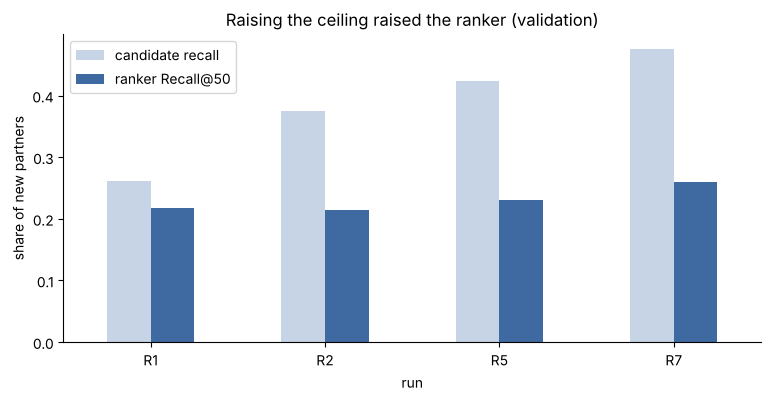

In [3]:
steps = pd.DataFrame([
    ("R1", "organic + kNN top-200", 0.262, 0.217),
    ("R2", "+ niche pool, kNN top-500", 0.375, 0.215),
    ("R5", "+ SVD embeddings", 0.424, 0.230),
    ("R7", "+ LightGCN", 0.476, 0.260),
], columns=["run", "candidate sources", "candidate recall", "ranker Recall@50"]).set_index("run")
ax = steps[["candidate recall", "ranker Recall@50"]].plot.bar(rot=0, color=["#c6d4e6", "#3f6aa1"])
ax.set_title("Raising the ceiling raised the ranker (validation)"); ax.set_ylabel("share of new partners")
steps

The biggest gains came from **better candidates**, not from more features. Even so, about half of the new partners are
never retrieved: brands choose among ~21k active, experienced creators for reasons this data does not contain
(budgets, agencies, personal contacts, negotiations).

## 2. The experiment path

> **Term — LightGCN:** a graph neural network for recommendation. Every brand and creator gets a learnable vector;
> in each layer a node averages its neighbours' vectors (a brand learns from its creators, then from those creators'
> other brands). It is trained with **BPR** loss: a connected brand–creator pair must score higher than a random pair.

,change,Recall@50,NDCG@50,decision
run,,,,
H,"heuristic: organic mentions, kNN breaks ties",0.207,0.113,reference
R1,"LightGBM ranker, first version",0.217,0.119,superseded
R4,+ brand partner-size features,0.220,0.123,superseded
R5,+ SVD candidates and features,0.230,0.126,superseded
R6,+ partner-profile features,0.229,0.125,rejected: no gain
R7,+ LightGCN candidates and features,0.260,0.135,final
R8,"+ time-decayed LightGCN, audience proxies",0.257,0.135,rejected: no gain


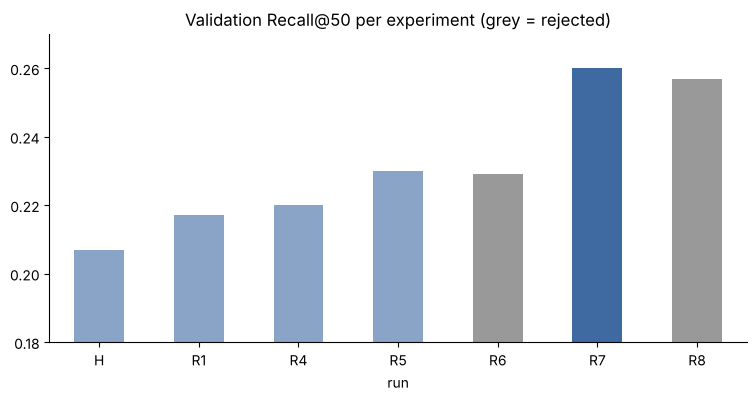

In [4]:
runs = pd.DataFrame([
    ("H", "heuristic: organic mentions, kNN breaks ties", 0.207, 0.113, "reference"),
    ("R1", "LightGBM ranker, first version", 0.217, 0.119, "superseded"),
    ("R4", "+ brand partner-size features", 0.220, 0.123, "superseded"),
    ("R5", "+ SVD candidates and features", 0.230, 0.126, "superseded"),
    ("R6", "+ partner-profile features", 0.229, 0.125, "rejected: no gain"),
    ("R7", "+ LightGCN candidates and features", 0.260, 0.135, "final"),
    ("R8", "+ time-decayed LightGCN, audience proxies", 0.257, 0.135, "rejected: no gain"),
], columns=["run", "change", "Recall@50", "NDCG@50", "decision"]).set_index("run")
colors = ["#999999" if d.startswith("rej") else ("#3f6aa1" if d == "final" else "#8aa4c8") for d in runs.decision]
ax = runs["Recall@50"].plot.bar(rot=0, color=colors)
ax.set_ylim(0.18, 0.27); ax.set_title("Validation Recall@50 per experiment (grey = rejected)")
runs

Two rejected experiments are as informative as the accepted ones:

* **R6** added features describing the partners a brand had chosen. No gain — kNN and SVD already encode “brands like
  you chose these creators”. Redundant features only add cost and overfitting risk, so they were removed.
* **R8** made LightGCN itself much better (alone: Recall@50 0.179 → 0.203 with time-decayed edges), yet the ranker did
  not improve: it already knew about recency from `days_since_org_mention`. **A better component is not automatically
  a better system.**

> **Term — noise level:** re-running the same configuration gives slightly different numbers (random negative sampling,
> random LightGCN initialisation): about ±0.005 Recall@50 here. Smaller differences are not evidence of anything.

## 3. Walk-forward validation

> **Term — walk-forward (time-series) cross-validation:** ordinary k-fold would train on the future and test on the
> past. Instead the boundary moves forward in time and each fold learns only from data before its evaluation window.

model,heuristic,ranker,gain
Jul–Sep 2018,0.187,0.226,+21%
Oct–Dec 2018,0.207,0.255,+23%


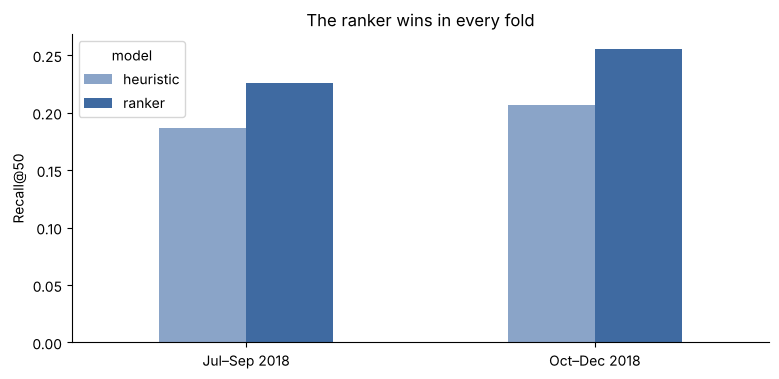

In [5]:
wf = pd.DataFrame(load("walk_forward.json")["per_fold"])
wf = wf[wf.model.isin(["organic only", "ranker"])].replace({"organic only": "heuristic"})
table = wf.pivot(index="fold", columns="model", values="recall@50").loc[["fold1", "val"]]
table["gain"] = table.ranker / table.heuristic - 1
table.index = ["Jul–Sep 2018", "Oct–Dec 2018"]
display(table.style.format({"heuristic": "{:.3f}", "ranker": "{:.3f}", "gain": "{:+.0%}"}))
ax = table[["heuristic", "ranker"]].plot.bar(rot=0, color=["#8aa4c8", "#3f6aa1"])
ax.set_ylabel("Recall@50"); ax.set_title("The ranker wins in every fold");

## 4. Final test — run once, model frozen

> **Why only once?** Every decision above was made by looking at validation numbers, which makes them slightly
> optimistic (we kept what happened to score well, luck included). The test period (Jan–Apr 2019) was never looked at,
> so it gives an unbiased estimate. April 2019 is incomplete (collection ended), which lowers every model equally.

,recall@10,recall@50,recall@100,ndcg@50
heuristic,0.124,0.214,0.261,0.113
kNN only,0.075,0.145,0.188,0.070
ranker,0.150,0.276,0.344,0.142
gain over heuristic,+21%,+29%,+32%,+26%


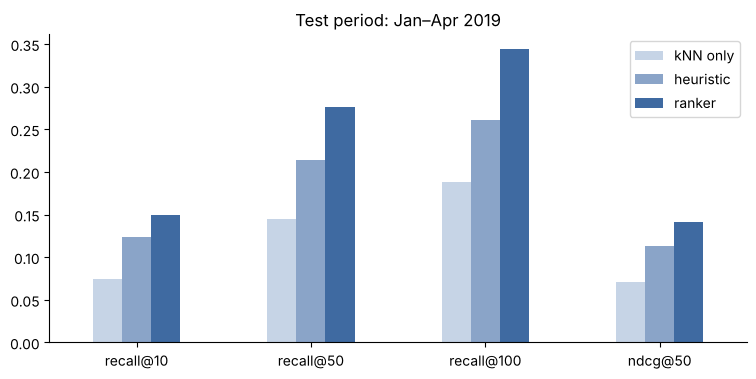

In [6]:
test = load("ranker_test.json")
summary = pd.DataFrame(test["summary"]).T.rename(index={"organic only": "heuristic"})
cols = ["recall@10", "recall@50", "recall@100", "ndcg@50"]
gain = (summary.loc["ranker", cols] / summary.loc["heuristic", cols] - 1).rename("gain over heuristic")
display(pd.concat([summary[cols], gain.to_frame().T]).style.format("{:.3f}").format("{:+.0%}", subset=pd.IndexSlice["gain over heuristic", :]))
ax = summary.loc[["kNN only", "heuristic", "ranker"], cols].T.plot.bar(rot=0, color=["#c6d4e6", "#8aa4c8", "#3f6aa1"])
ax.set_title("Test period: Jan–Apr 2019"); ax.legend(title="");

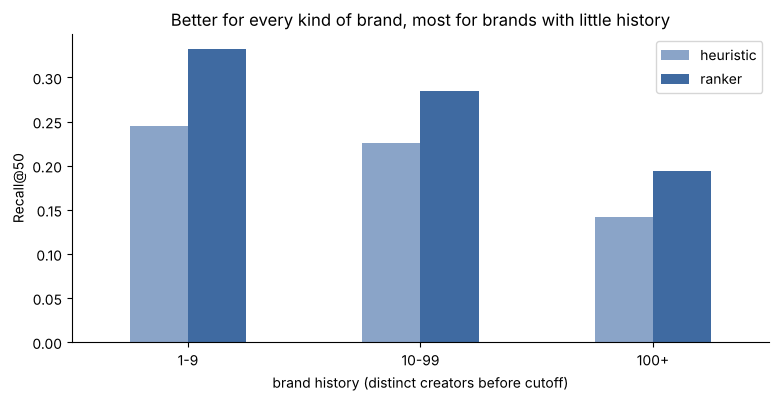

In [7]:
b = pd.DataFrame(test["recall50_by_bucket"]).rename(columns={"organic only": "heuristic"}).drop(index="cold (0)", errors="ignore")
ax = b[["heuristic", "ranker"]].plot.bar(rot=0, color=["#8aa4c8", "#3f6aa1"])
ax.set_xlabel("brand history (distinct creators before cutoff)"); ax.set_ylabel("Recall@50")
ax.set_title("Better for every kind of brand, most for brands with little history");

The test result (+29% Recall@50 over the heuristic) matches walk-forward (+21%, +23%). The absolute numbers are a bit
higher than on validation, most likely because the model is trained on more recent data and brands have more history
by 2019 — the same upward drift seen across walk-forward folds. The **relative gain** is the robust claim.

## 5. Popularity bias

> **Term — popularity bias:** a tendency to recommend already-big accounts. Not wrong in itself, but if every brand
> gets the same big names, smaller creators never get a chance and campaigns get expensive.

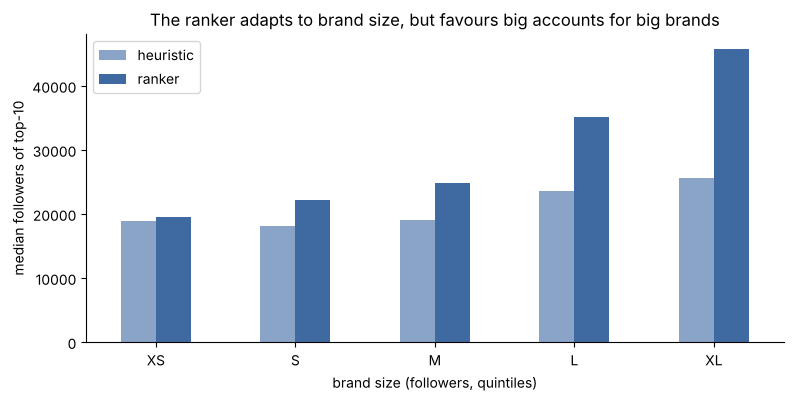

In [8]:
bias = pd.DataFrame(test["top10_followers_by_brand_size"]).rename(columns={"organic only": "heuristic"})
ax = bias[["heuristic", "ranker"]].plot.bar(rot=0, color=["#8aa4c8", "#3f6aa1"])
ax.set_xlabel("brand size (followers, quintiles)"); ax.set_ylabel("median followers of top-10")
ax.set_title("The ranker adapts to brand size, but favours big accounts for big brands");

Small brands get small creators (it mirrors what similar brands actually did). For the largest brands the ranker leans
towards bigger accounts than the heuristic. In the app this is handled as a **business rule**, not a model change: the
marketer can filter by creator size or ask for a share of smaller creators in the shortlist.

## 6. What the model relies on

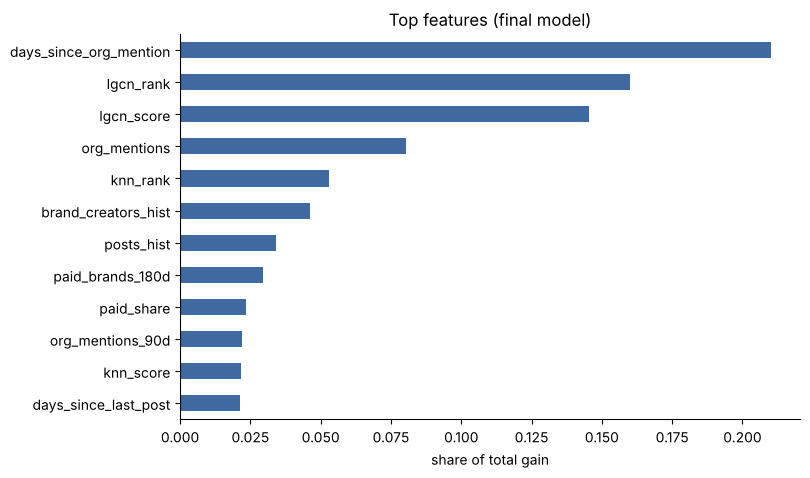

In [9]:
imp = pd.Series(test["feature_importance"]).sort_values()
ax = imp.tail(12).plot.barh(color="#3f6aa1", figsize=(8, 5))
ax.set_xlabel("share of total gain"); ax.set_title("Top features (final model)");

> **Term — feature importance (gain):** how much the model's loss improved from splits on that feature. It shows what
> the model *uses*, not what *causes* a collaboration.

Recency of an organic mention and the LightGCN score dominate; kNN, niche fit, creator experience and brand size
fine-tune the order.

## Limitations

* **Implicit data:** we see who collaborated, not who was considered and rejected; unseen ≠ uninterested.
* **About half of new partners are never retrieved** — the decisive factors are not in public posts.
* **Offline evaluation only:** no A/B test with real marketers; the app logs accepted/rejected suggestions so an
  online evaluation would be possible.
* **Data from 2017–2019, research-only licence:** methods transfer, the trained model does not.
* **True cold start barely exists** in this data (almost every brand had been mentioned before), so it is not evaluated.

## Next steps

* Caption **language** as a market signal (the one audience property not visible in the graph).
* **Visual style** from images (CLIP embeddings), mostly for brands with little history.
* Explanations generated from the features the model actually used, with automatic faithfulness checks.